# Tas vs Tas

Historical

Figure saved as 'Global_vs_Regional_Temp_Winter0.png'


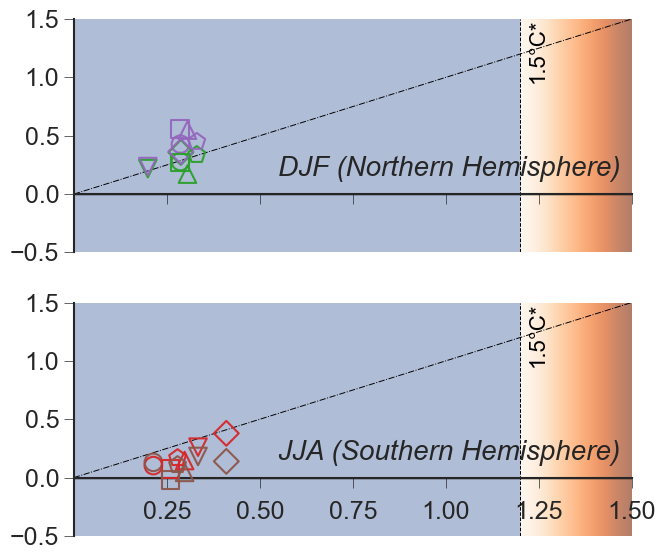

In [1]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSTas_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_°C"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    # Orange gradient only for the 1.7–2.0 zone
    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.5, 1.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_°C"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.50
    y_max = 1.5
    xticks = np.arange(0.25, x_max + 0.01, 0.25)
    yticks = np.arange(y_min, y_max + 0.01, 0.5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.plot([0, x_max], [0, y_max], '-.', color='black', linewidth=0.7, label="1:1 Reference")
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 1.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.3, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.3, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Create Legend Elements ===
# Region colors legend
region_legend = [
    Line2D([0], [0], marker='o', color='w', label='NSZ',
           markerfacecolor='none', markeredgecolor=region_colors['Subtropics_N'], 
           markersize=8, markeredgewidth=1.5, linestyle='None'),
    Line2D([0], [0], marker='o', color='w', label='SSZ',
           markerfacecolor='none', markeredgecolor=region_colors['Subtropics_S'], 
           markersize=8, markeredgewidth=1.5, linestyle='None'),
    Line2D([0], [0], marker='o', color='w', label='NMZ',
           markerfacecolor='none', markeredgecolor=region_colors['Mid_Latitudes_N'], 
           markersize=8, markeredgewidth=1.5, linestyle='None'),
    Line2D([0], [0], marker='o', color='w', label='SMZ',
           markerfacecolor='none', markeredgecolor=region_colors['Mid_Latitudes_S'], 
           markersize=8, markeredgewidth=1.5, linestyle='None'),
]

# Model markers legend
model_legend = [
    Line2D([0], [0], marker=marker, color='w', label=model,
           markerfacecolor='none', markeredgecolor='black', 
           markersize=8, markeredgewidth=1.5, linestyle='None')
    for model, marker in model_markers.items()
]

# Add shared axis labels
#fig.text(0.5, 0.02, 'Global Temperature Change (°C)', 
#         ha='center', fontweight='bold', fontsize=16)
#fig.text(0.01, 0.5, 'Regional Temperature Change (°C)', 
#         va='center', rotation='vertical', fontweight='bold', fontsize=16)
         
# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_vs_Regional_Temp_Winter0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_vs_Regional_Temp_Winter0.png'")
plt.show()

Figure saved as 'Global_vs_Regional_Temp_Summer0.png'


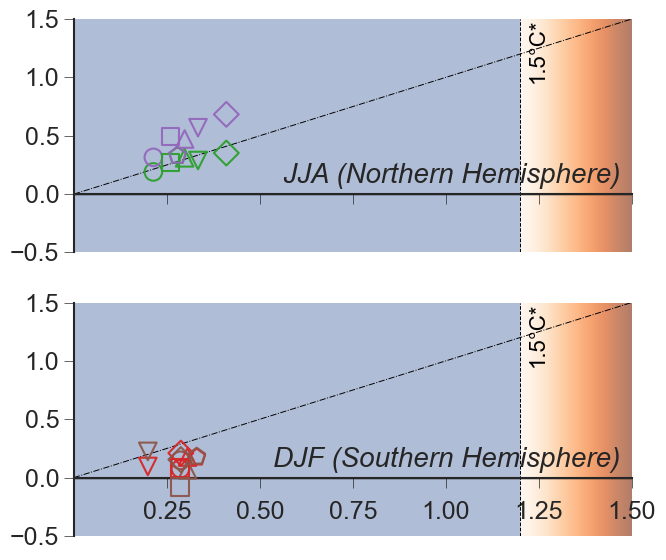

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSTas_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_°C"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    # Orange gradient only for the 1.7–2.0 zone
    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.5, 1.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_°C"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.5
    y_max = 1.5
    xticks = np.arange(0.25, x_max + 0.01, 0.25)
    yticks = np.arange(y_min, y_max + 0.01, 0.5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.plot([0, x_max], [0, y_max], '-.', color='black', linewidth=0.7, label="1:1 Reference")
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1.0, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 1.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.27, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.27, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# Add shared axis labels
#fig.text(0.5, 0.02, 'Global Temperature Change (°C)', 
#         ha='center', fontweight='bold', fontsize=16)
#fig.text(0.01, 0.5, 'Regional Temperature Change (°C)', 
#         va='center', rotation='vertical', fontweight='bold', fontsize=16)

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_vs_Regional_Temp_Summer0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_vs_Regional_Temp_Summer0.png'")
plt.show()

Midterm

Figure saved as 'Global_vs_Regional_Temp_Winter1.png'


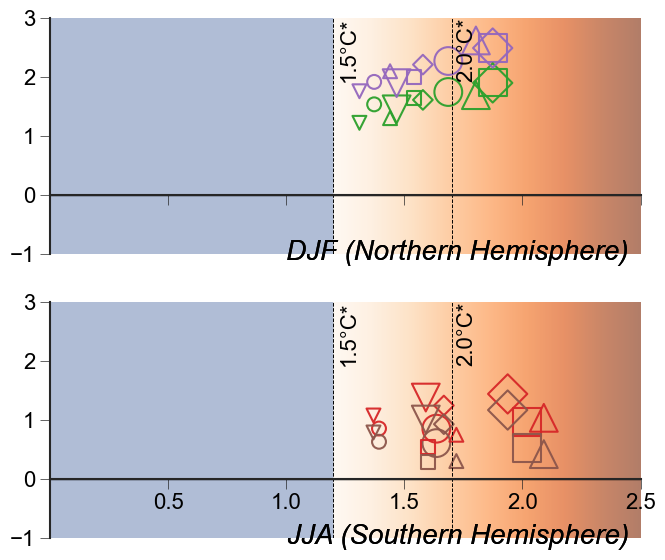

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSTas_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    #'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_°C"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=1.0, color='#A8B4CC', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1, color='#F2B89A', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    # Orange gradient only for the 1.7–2.0 zone
    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -1, 3],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_°C"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -1
    y_max = 3.0
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 1)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 3, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.02, 3, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    #ax.plot([0, x_max], [0, x_max], '-.', color='black', linewidth=0.7, label="1:1 Reference")

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)


    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, -0.05, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic', color='black')
    axs[1].text(0.98, -0.05, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic', color='black')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='black', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# Add shared axis labels
#fig.text(0.5, 0.02, 'Global Temperature Change (°C)', 
#         ha='center', fontweight='bold', fontsize=16)
#fig.text(0.01, 0.5, 'Regional Temperature Change (°C)', 
#         va='center', rotation='vertical', fontweight='bold', fontsize=16)

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
#plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.tight_layout(rect=[0, 0.01, 1, 1])
fig.set_size_inches(7, 6)  # enforce size after tight_layout
plt.savefig("Global_vs_Regional_Temp_Winter1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_vs_Regional_Temp_Winter1.png'")
plt.show()

Figure saved as 'Global_vs_Regional_Temp_Summer1.png'


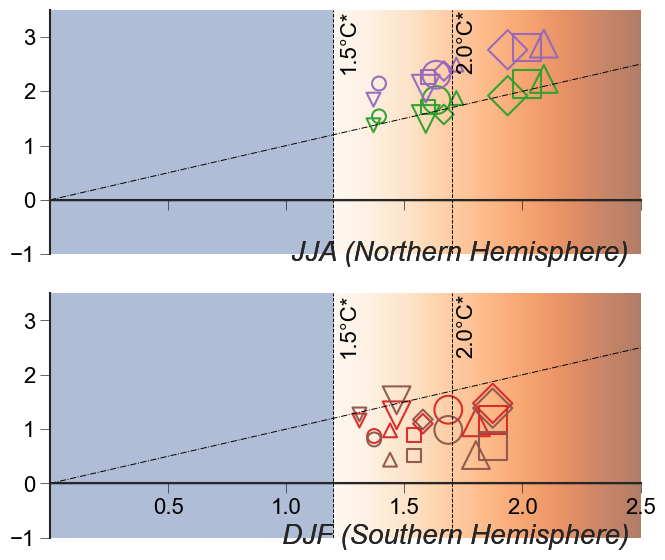

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSTas_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v'       # Changed from 'd' to inverted triangle
    #'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_°C"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    # Orange gradient only for the 1.7–2.0 zone
    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -1, 3.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_°C"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -1
    y_max = 3.5
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 1)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 3.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.02, 3.5, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.plot([0, x_max], [0, x_max], '-.', color='black', linewidth=0.7, label="1:1 Reference")
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, -0.05, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, -0.05, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='black', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# Add shared axis labels
#fig.text(0.5, 0.02, 'Global Temperature Change (°C)', 
#         ha='center', fontweight='bold', fontsize=16)
#fig.text(0.01, 0.5, 'Regional Temperature Change (°C)', 
#         va='center', rotation='vertical', fontweight='bold', fontsize=16)
         
# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
#plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.tight_layout(rect=[0, 0.01, 1, 1])
fig.set_size_inches(7, 6)  # enforce size after tight_layout
plt.savefig("Global_vs_Regional_Temp_Summer1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_vs_Regional_Temp_Summer1.png'")
plt.show()

Longterm

Figure saved as 'Global_vs_Regional_Temp_Winter2.png'


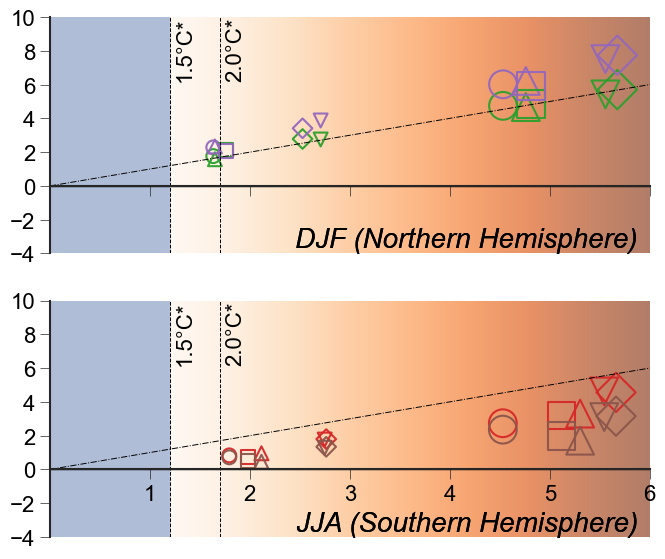

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSTas_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_°C"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    # Orange gradient only for the 1.7–2.0 zone
    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -4, 10],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_°C"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -4
    y_max = 10
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 2)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1.0)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 10, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 10, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.plot([0, x_max], [0, x_max], '-.', color='black', linewidth=0.7, label="1:1 Reference")
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic', color='black')
    axs[1].text(0.98, 0, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic', color='black')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# Add shared axis labels
#fig.text(0.5, 0.02, 'Global Temperature Change (°C)', 
#         ha='center', fontweight='bold', fontsize=16)
#fig.text(0.01, 0.5, 'Regional Temperature Change (°C)', 
#         va='center', rotation='vertical', fontweight='bold', fontsize=16)

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
#plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.tight_layout(rect=[0, 0.01, 1, 1])
fig.set_size_inches(7, 6)  # enforce size after tight_layout
plt.savefig("Global_vs_Regional_Temp_Winter2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_vs_Regional_Temp_Winter2.png'")
plt.show()

Figure saved as 'Global_vs_Regional_Temp_Summer2.png'


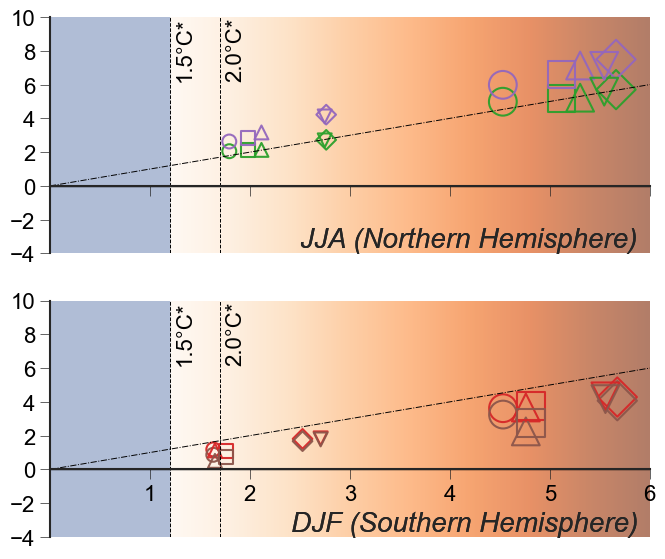

In [17]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSTas_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_°C"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#F5C4A0', zorder=0)
    # Orange gradient only for the 1.7–2.0 zone
    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -4, 10],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_°C"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -4
    y_max = 10
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 2)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16, labelcolor='black')

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 10, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 10, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.plot([0, x_max], [0, x_max], '-.', color='black', linewidth=0.7, label="1:1 Reference")
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.0, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.0, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='black', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# Add shared axis labels
#fig.text(0.5, 0.02, 'Global Temperature Change (°C)', 
#         ha='center', fontsize=16)
#fig.text(0.01, 0.5, 'Regional Temperature Change (°C)', 
#         va='center', rotation='vertical', fontweight='bold', fontsize=16)

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_vs_Regional_Temp_Summer2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_vs_Regional_Temp_Summer2.png'")
plt.show()

# Tas vs Prw

Historical

Figure saved as 'Global_Temp_vs_Prw_Winter0.png'


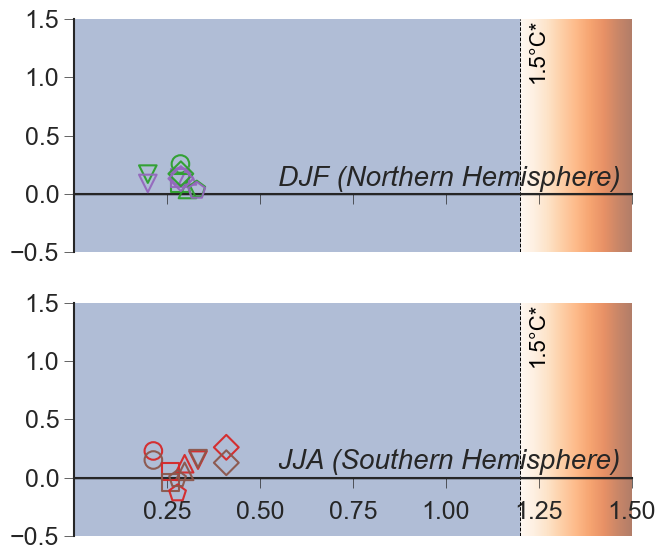

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPrw_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.5, 1.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.5
    y_max = 1.5
    xticks = np.arange(0.25, x_max + 0.01, 0.25)
    yticks = np.arange(y_min, y_max + 0.01, 0.5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 1.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    #ax.plot([0, 1.5], [0, 1.5], '-.', color='black', linewidth=0.7, label="1:1 Reference") #for analysis purposes only
    # === Clausius-Clapeyron scaling reference ===
    #CC_rate = 0.07  # ~7%/°C, standard theoretical CC scaling rate (adjust if you're using a different value, e.g. 0.06-0.075)
    #ax.plot([0, x_max], [0, CC_rate * x_max], '-.', color='black', linewidth=0.7, label="CC Scaling (7%/°C)")

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.26, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.26, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Prw_Winter0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Prw_Winter0.png'")
plt.show()

Figure saved as 'Global_Temp_vs_Prw_Summer0.png'


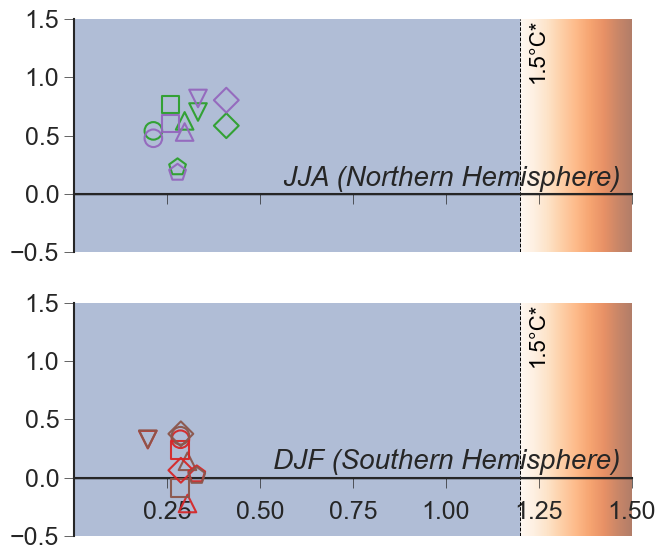

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPrw_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.5, 1.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.5
    y_max = 1.5
    xticks = np.arange(0.25, x_max + 0.01, 0.25)
    yticks = np.arange(y_min, y_max + 0.01, 0.5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 1.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    #ax.plot([0, 1.5], [0, 1.5], '-.', color='black', linewidth=0.7, label="1:1 Reference") #for analysis purposes only
    # === Clausius-Clapeyron scaling reference ===
    #CC_rate = 0.07  # ~7%/°C, standard theoretical CC scaling rate (adjust if you're using a different value, e.g. 0.06-0.075)
    #ax.plot([0, x_max], [0, CC_rate * x_max], '-.', color='black', linewidth=0.7, label="CC Scaling (7%/°C)")

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.26, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.26, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Prw_Summer0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Prw_Summer0.png'")
plt.show()

Midterm

Figure saved as 'Global_Temp_vs_Prw_Winter1.png'


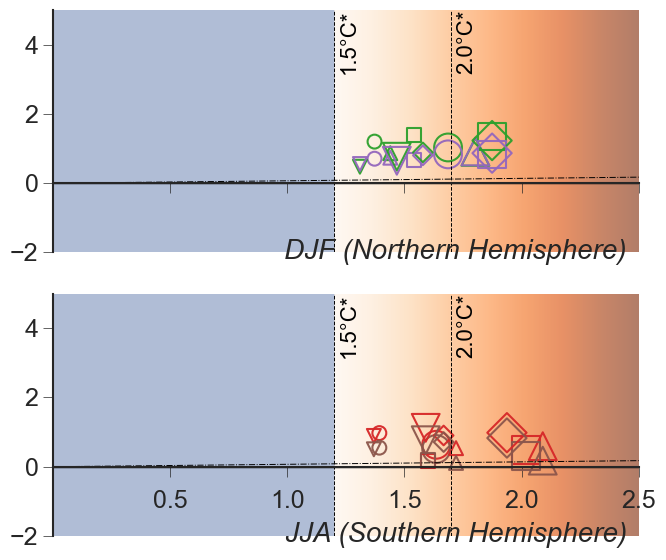

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPrw_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)

    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -2, 5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -2
    y_max = 5.0
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 2)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1.0, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7, zorder=2)

    #ax.plot([0, 2.5], [0, 2.5], '-.', color='black', linewidth=0.7, label="1:1 Reference") #for analysis purposes only
    # === Clausius-Clapeyron scaling reference ===
    CC_rate = 0.07  # ~7%/°C, standard theoretical CC scaling rate (adjust if you're using a different value, e.g. 0.06-0.075)
    ax.plot([0, x_max], [0, CC_rate * x_max], '-.', color='black', linewidth=0.7, label="CC Scaling (7%/°C)")

    ax.text(1.2 + 0.02, 5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.02, 5, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')


    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, -0.05, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, -0.05, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Prw_Winter1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Prw_Winter1.png'")
plt.show()

Figure saved as 'Global_Temp_vs_Prw_Summer1.png'


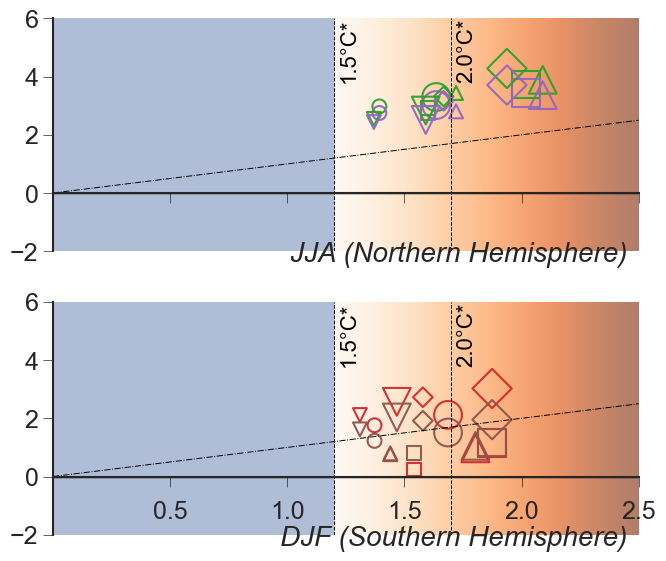

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPrw_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)

    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -2, 6],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -2
    y_max = 6.0
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 2)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.plot([0, 2.5], [0, 2.5], '-.', color='black', linewidth=0.7, label="1:1 Reference") #for analysis purposes only
    
    ax.text(1.2 + 0.02, 6, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.02, 6, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')


    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, -0.07, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, -0.07, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Prw_Summer1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Prw_Summer1.png'")
plt.show()

Longterm

Figure saved as 'Global_Temp_vs_Prw_Winter2.png'


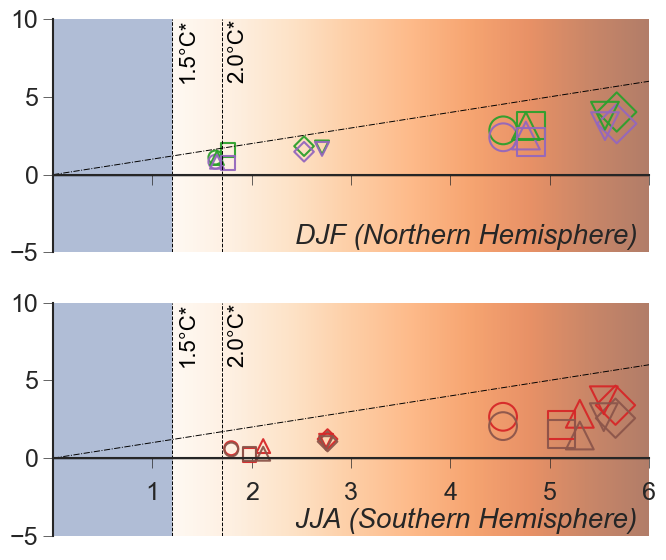

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPrw_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)

    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -5, 10],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6.0
    y_min = -5
    y_max = 10.0
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.plot([0, 6.0], [0, 6.0], '-.', color='black', linewidth=0.7, label="1:1 Reference") #for analysis purposes only
    
    ax.text(1.2 + 0.05, 10, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 10, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')


    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.01, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.01, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Prw_Winter2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Prw_Winter2.png'")
plt.show()

Figure saved as 'Global_Temp_vs_Prw_Summer2.png'


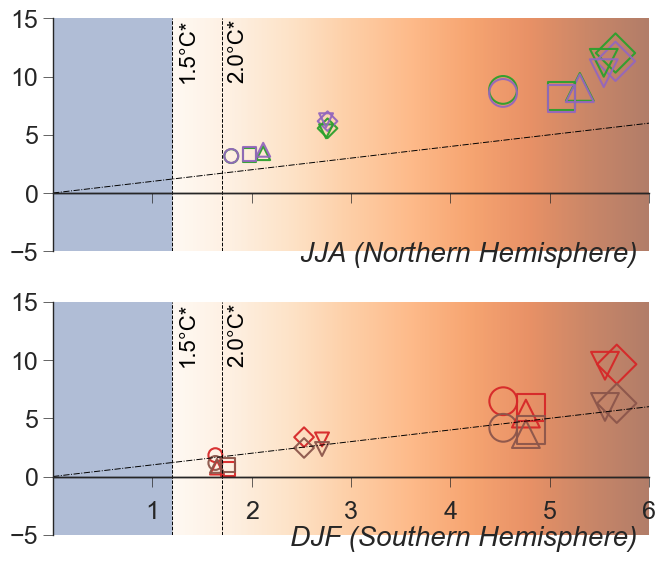

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPrw_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)

    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -5, 15],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6.0
    y_min = -5
    y_max = 15.0
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7, zorder=2)
    ax.plot([0, 6], [0, 6], '-.', color='black', linewidth=0.7, label="1:1 Reference") #for analysis purposes only
    
    ax.text(1.2 + 0.05, 15, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 15, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')


    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.0)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.0)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, -0.07, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, -0.07, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Prw_Summer2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Prw_Summer2.png'")
plt.show()

# Tas vs Pr

Historical

Figure saved as 'Global_Temp_vs_Pr_Winter0.png'


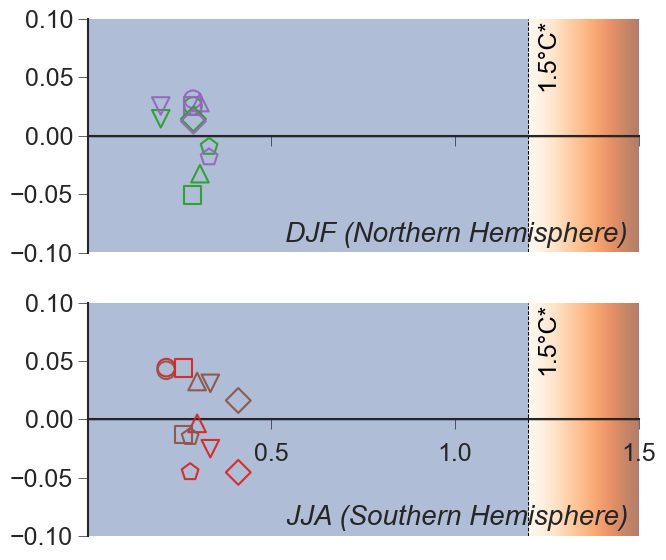

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPr_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.1, 0.1],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.1
    y_max = 0.1
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.05)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 0.1, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Pr_Winter0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Pr_Winter0.png'")
plt.show()

Figure saved as 'Global_Temp_vs_Pr_Summer0.png'


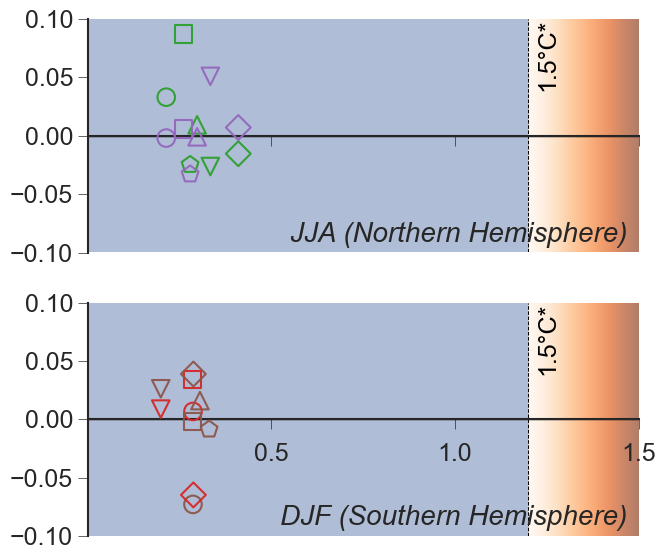

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPr_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.1, 0.1],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.1
    y_max = 0.1
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.05)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 0.1, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Pr_Summer0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Pr_Summer0.png'")
plt.show()

Midterm

Figure saved as 'Global_Temp_vs_Pr_Winter1.png'


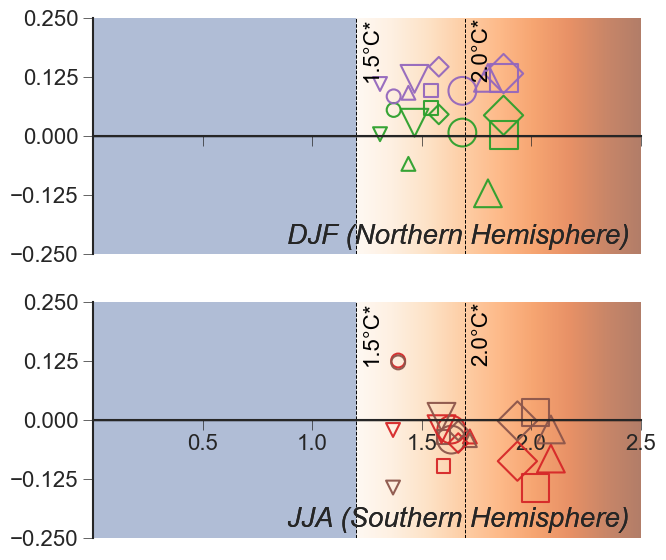

In [39]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPr_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -0.25, 0.25],
              origin='lower', alpha=0.6, zorder=0)


    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -0.25
    y_max = 0.25
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.125)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.025, 0.25, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.025, 0.25, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Pr_Winter1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Pr_Winter1.png'")
plt.show()

Figure saved as 'Global_Temp_vs_Pr_Summer1.png'


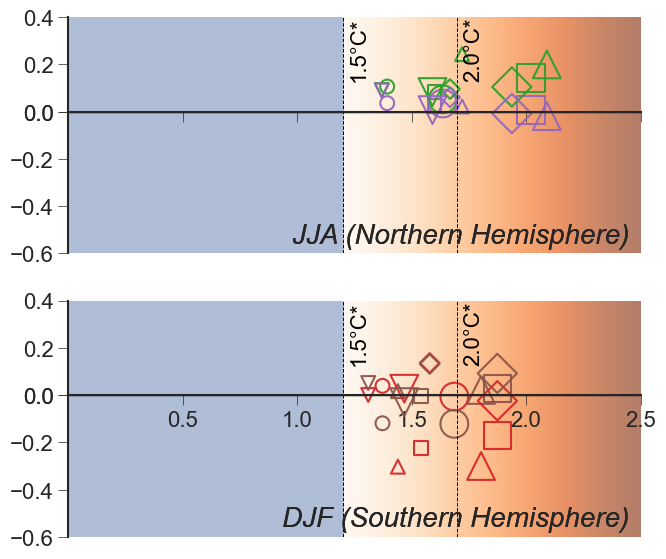

In [54]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPr_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -0.6, 0.4],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -0.6
    y_max = 0.4
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.2)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.025, 0.4, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.025, 0.4, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Pr_Summer1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Pr_Summer1.png'")
plt.show()

Longterm

Figure saved as 'Global_Temp_vs_Pr_Winter2.png'


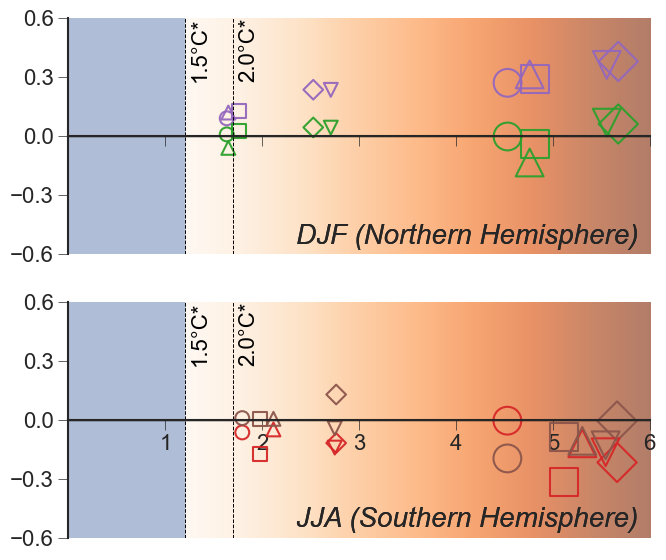

In [57]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPr_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Longterm
    '585_Longterm': 400    # Larger size for 585_Longterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -0.6, 0.6],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -0.6
    y_max = 0.6
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 0.3)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 0.6, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 0.6, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Pr_Winter2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Pr_Winter2.png'")
plt.show()

Figure saved as 'Global_Temp_vs_Pr_Summer2.png'


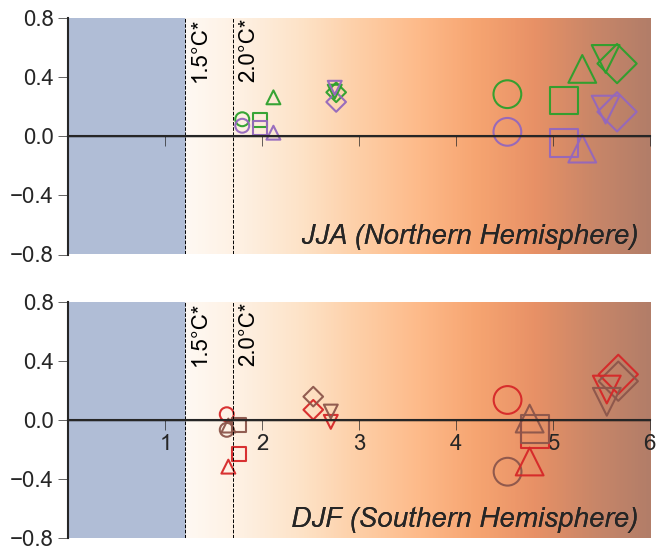

In [61]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSPr_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Longterm
    '585_Longterm': 400    # Larger size for 585_Longterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -0.8, 0.8],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -0.8
    y_max = 0.8
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 0.4)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 0.8, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 0.8, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_Pr_Summer2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_Pr_Summer2.png'")
plt.show()

# Tas vs ET

Historical

Figure saved as 'Global_Temp_vs_E_Winter0.png'


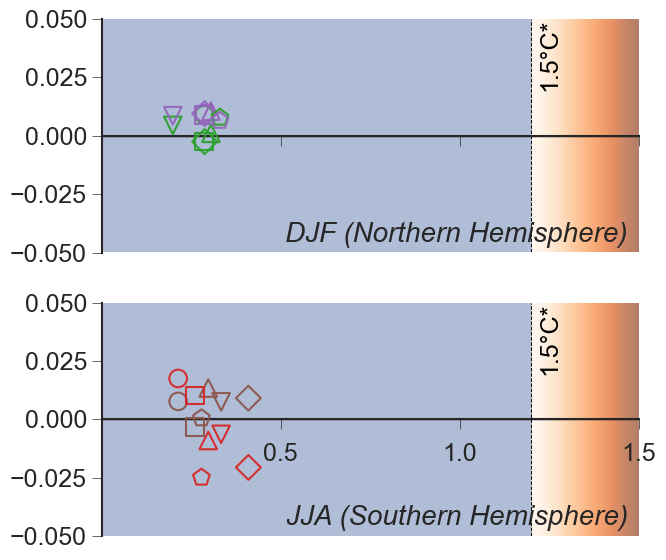

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSE_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)


    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.1, 0.1],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.05
    y_max = 0.05
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.025)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 0.05, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_E_Winter0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_E_Winter0.png'")
plt.show()

Figure saved as 'Global_Temp_vs_E_Summer0.png'


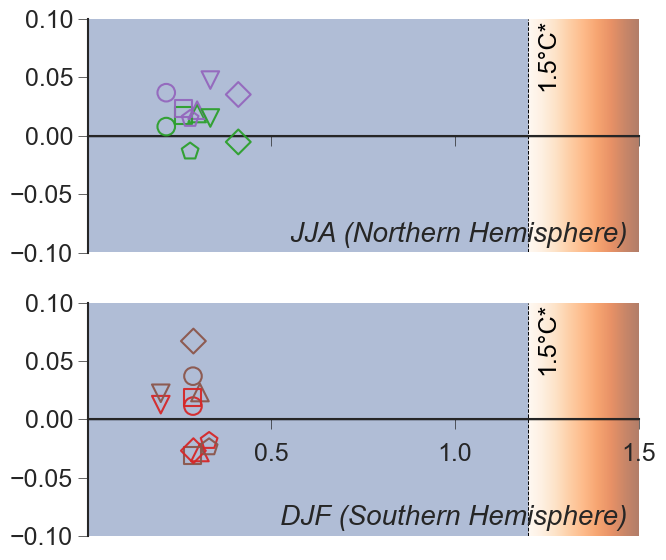

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSE_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)


    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.1, 0.1],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.1
    y_max = 0.1
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.05)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 0.1, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_E_Summer0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_E_Summer0.png'")
plt.show()

Midterm

Figure saved as 'Global_Temp_vs_E_Winter1.png'


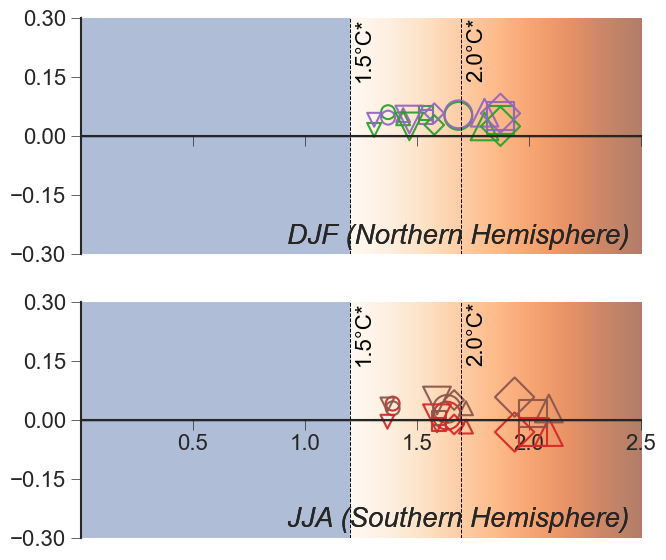

In [71]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSE_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -0.3, 0.3],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -0.3
    y_max = 0.3
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.15)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 0.3, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.02, 0.3, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_E_Winter1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_E_Winter1.png'")
plt.show()

Figure saved as 'Global_Temp_vs_E_Summer1.png'


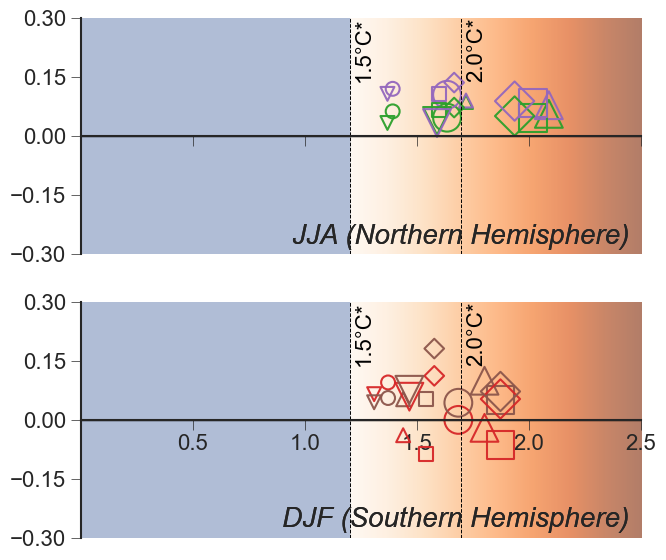

In [70]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSE_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -0.3, 0.3],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -0.3
    y_max = 0.3
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.15)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 0.3, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.02, 0.3, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_E_Summer1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_E_Summer1.png'")
plt.show()

Longterm

Figure saved as 'Global_Temp_vs_E_Winter2.png'


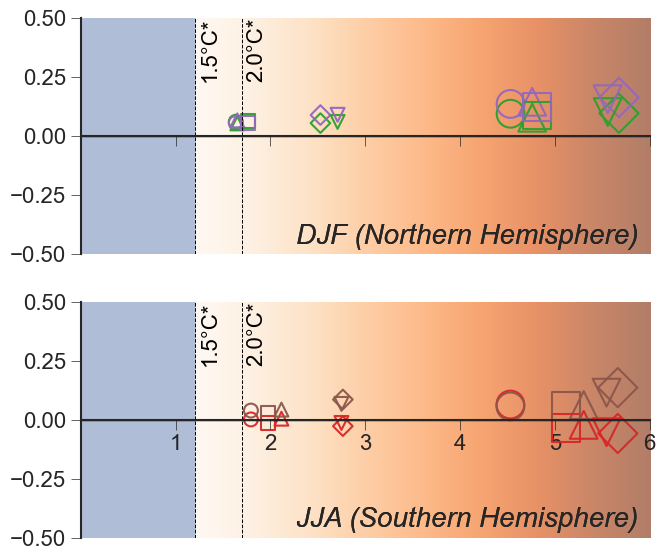

In [75]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSE_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -0.5, 0.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -0.5
    y_max = 0.5
    xticks = np.arange(1.0, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 0.25)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 0.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 0.5, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_E_Winter2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_E_Winter2.png'")
plt.show()

Figure saved as 'Global_Temp_vs_E_Summer2.png'


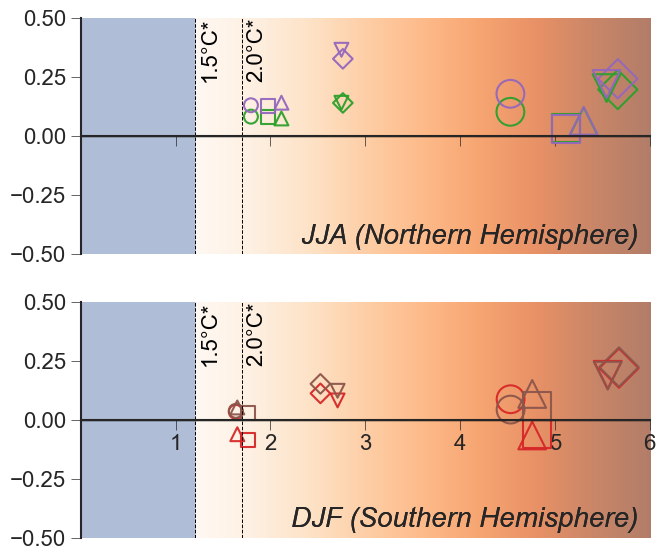

In [76]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSE_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -0.5, 0.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -0.5
    y_max = 0.5
    xticks = np.arange(1.0, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 0.25)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=16)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 0.5, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 0.5, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_E_Summer2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_E_Summer2.png'")
plt.show()

# Tas vs SM

Historical

Figure saved as 'Global_Temp_vs_SM_Winter0.png'


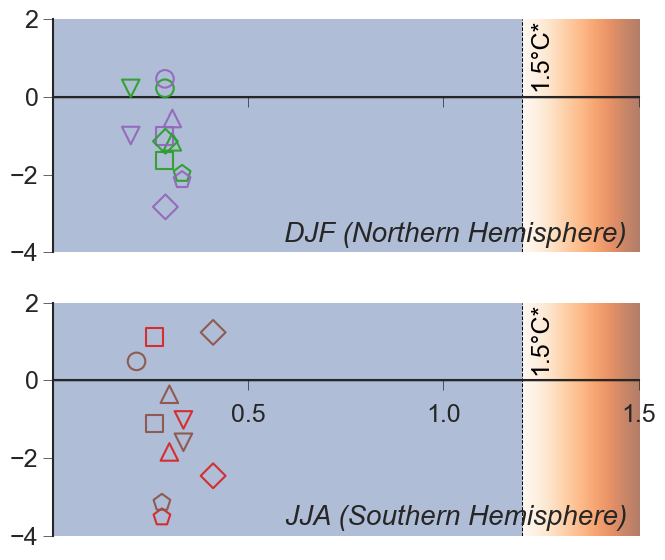

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSSM_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SCALE y-variable ===
df["Regional_change_m3/m3"] = df["Regional_change_m3/m3"] * 1000

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_m3/m3"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -4.0, 2.0],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_m3/m3"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -4
    y_max = 2
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 2)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 2, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_SM_Winter0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_SM_Winter0.png'")
plt.show()

Figure saved as 'Global_Temp_vs_SM_Summer0.png'


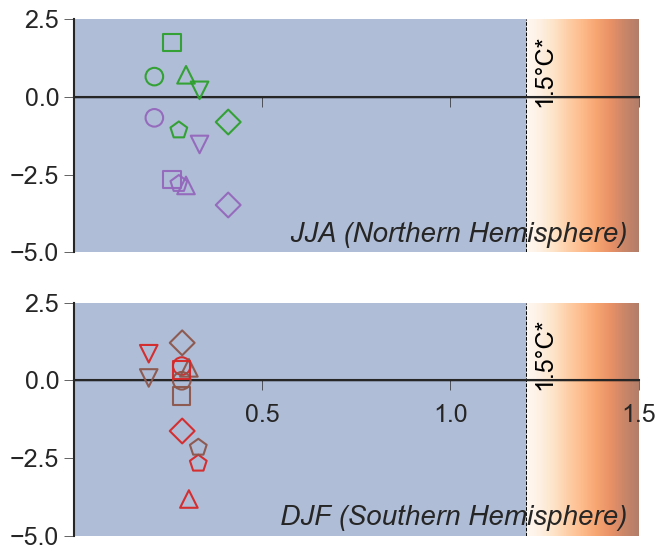

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSSM_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SCALE y-variable ===
df["Regional_change_m3/m3"] = df["Regional_change_m3/m3"] * 1000

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_m3/m3"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -5.0, 2.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_m3/m3"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -5
    y_max = 2.5
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 2.5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 2, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_SM_Summer0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_SM_Summer0.png'")
plt.show()

Midterm

Figure saved as 'Global_Temp_vs_SM_Winter1.png'


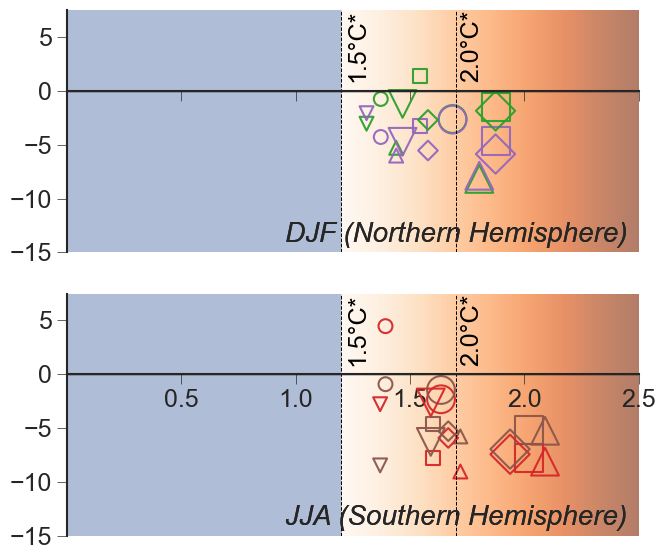

In [79]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSSM_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SCALE y-variable ===
df["Regional_change_m3/m3"] = df["Regional_change_m3/m3"] * 1000

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_m3/m3"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -15, 7.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_m3/m3"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -15
    y_max = 7.5
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 5)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 7.5, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.02, 7.5, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_SM_Winter1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_SM_Winter1.png'")
plt.show()

Figure saved as 'Global_Temp_vs_SM_Summer1.png'


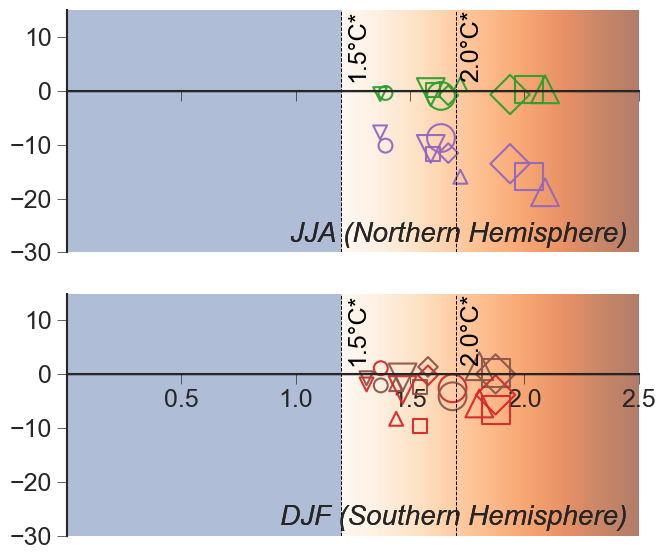

In [81]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSSM_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SCALE y-variable ===
df["Regional_change_m3/m3"] = df["Regional_change_m3/m3"] * 1000

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_m3/m3"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -30, 15],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_m3/m3"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -30
    y_max = 15
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 10)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 15, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.02, 15, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_SM_Summer1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_SM_Summer1.png'")
plt.show()

Longterm

Figure saved as 'Global_Temp_vs_SM_Winter2.png'


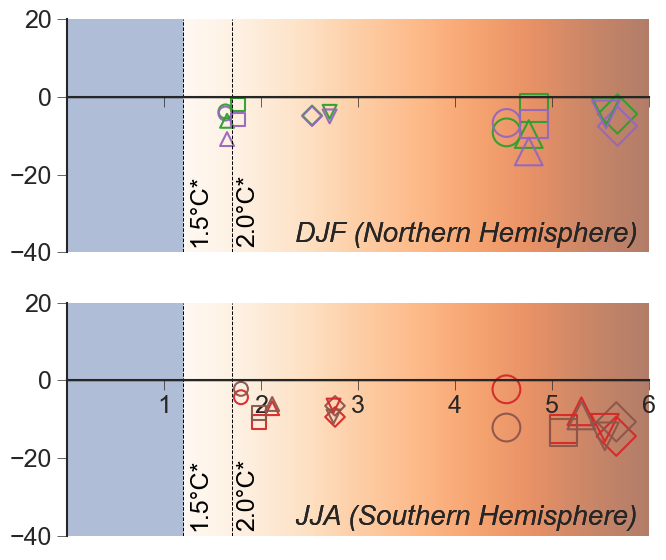

In [99]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSSM_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SCALE y-variable ===
df["Regional_change_m3/m3"] = df["Regional_change_m3/m3"] * 1000

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_m3/m3"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -40, 20],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_m3/m3"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -40
    y_max = 20
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 20)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, -20, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.05, -20, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_SM_Winter2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_SM_Winter2.png'")
plt.show()

Figure saved as 'Global_Temp_vs_SM_Summer2.png'


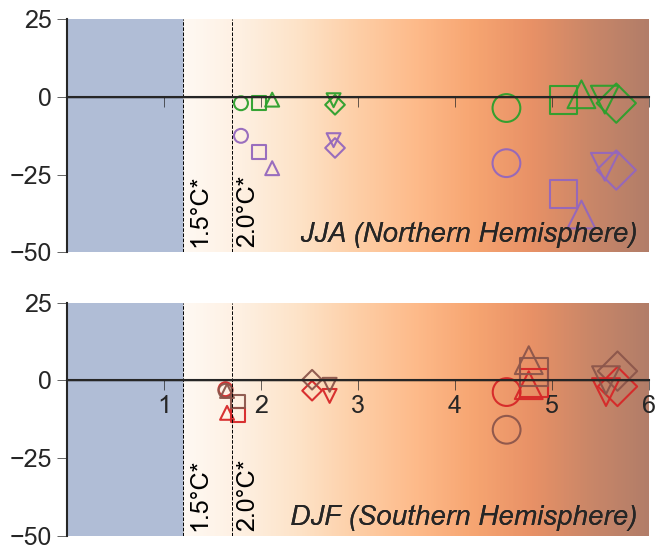

In [100]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSSM_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SCALE y-variable ===
df["Regional_change_m3/m3"] = df["Regional_change_m3/m3"] * 1000

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_m3/m3"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -50, 25],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_m3/m3"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -50
    y_max = 25
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 25)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, -25, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.05, -25, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_SM_Summer2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_SM_Summer2.png'")
plt.show()

# Tas vs q

Historical

Figure saved as 'Global_Temp_vs_q_Winter0.png'


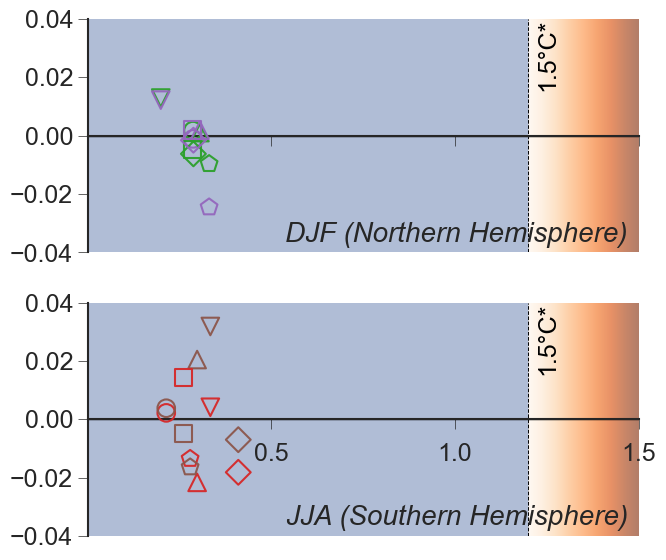

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSRunoff_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.04, 0.04],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.04
    y_max = 0.04
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.02)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 0.04, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_q_Winter0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_q_Winter0.png'")
plt.show()

Figure saved as 'Global_Temp_vs_q_Summer0.png'


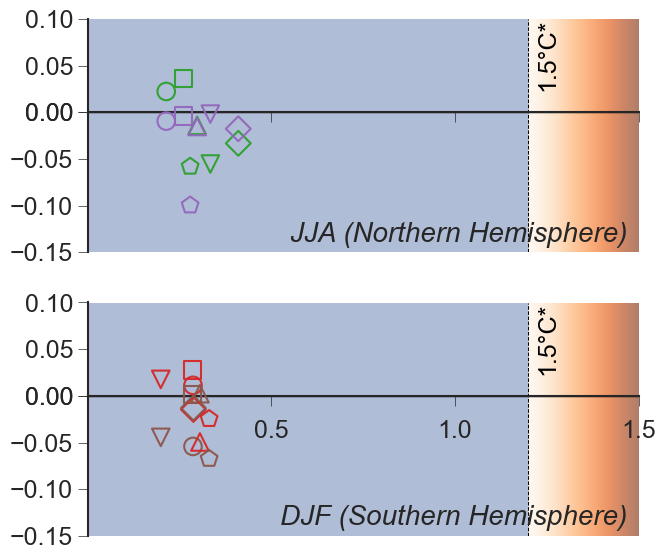

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSRunoff_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"] == "Historical"]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.5, alpha=0.6, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 1.5, -0.15, 0.1],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=160,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95,
                zorder=3          # Make sure markers are on top
            )

    x_max = 1.5
    y_min = -0.15
    y_max = 0.1
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.05)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    ax.axhline(y=0, color='black', linestyle='-', linewidth=1, zorder=2)
    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7, zorder=2)
    
    ax.text(1.2 + 0.02, 0.1, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')

    # === REMOVE SPINES (BORDER LINES) - KEEP ONLY X AND Y AXES ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Move X-axis to Y=0
    ax.spines['bottom'].set_position(('data', 0))
    
    ax.tick_params(axis='both', which='major', length=7, width=0.5, direction='out', labelsize=18)
    # Move X-axis tick labels to Y=0
    ax.tick_params(axis='x', which='major', pad=10)  # Add some padding below Y=0
    ax.grid(False)

# === ANNOTATIONS FOR SEASONS ===
axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')
axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
       fontsize=20, ha='right', va='bottom', style='italic')

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_q_Summer0.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_q_Summer0.png'")
plt.show()

Midterm

Figure saved as 'Global_Temp_vs_q_Winter1.png'


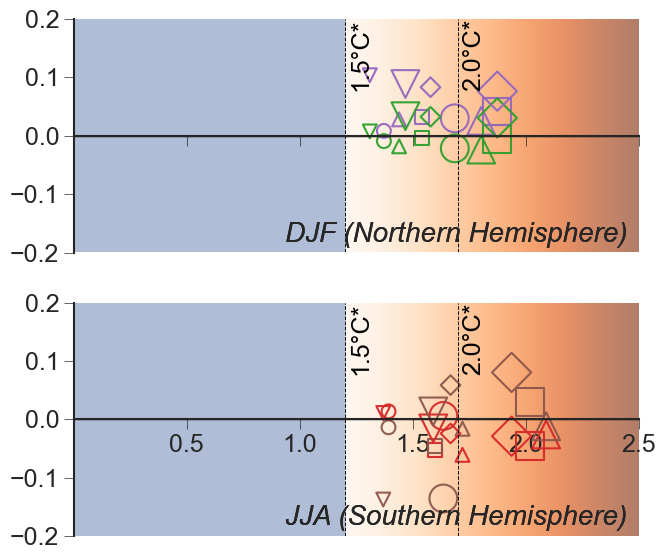

In [111]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSRunoff_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -0.2, 0.2],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -0.2
    y_max = 0.2
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.1)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 0.2, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.02, 0.2, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_q_Winter1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_q_Winter1.png'")
plt.show()

Figure saved as 'Global_Temp_vs_q_Summer1.png'


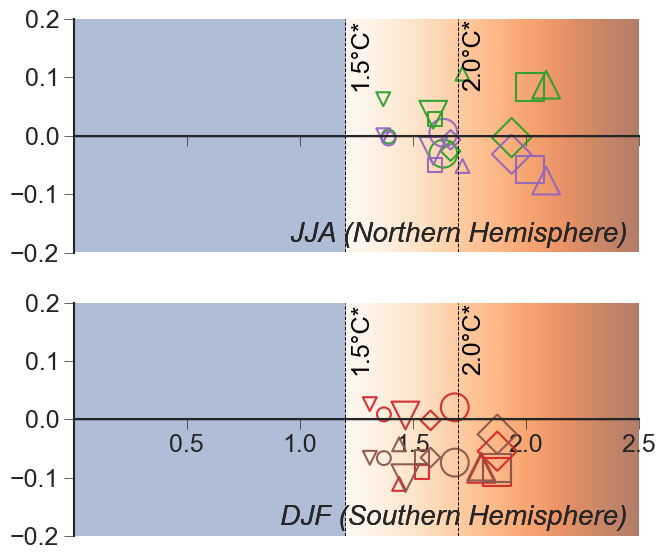

In [115]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSRunoff_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Midterm", "585_Midterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Midterm': 100,   # Smaller size for 126_Midterm
    '585_Midterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 2.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 2.5, -0.2, 0.2],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 2.5
    y_min = -0.2
    y_max = 0.2
    xticks = np.arange(0.5, x_max + 0.01, 0.5)
    yticks = np.arange(y_min, y_max + 0.01, 0.1)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.02, 0.2, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.02, 0.2, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_q_Summer1.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_q_Summer1.png'")
plt.show()

Longterm

Figure saved as 'Global_Temp_vs_q_Winter2.png'


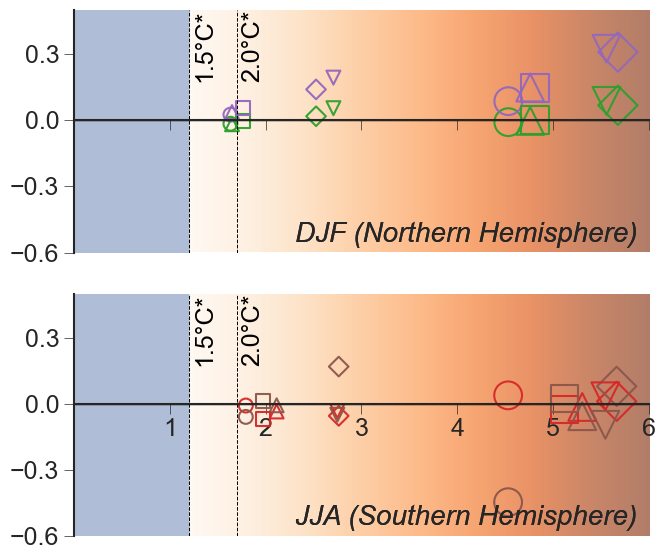

In [120]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSRunoff_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "DJF: Northern Hemisphere"
    },
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "JJA: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -0.6, 0.5],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -0.6
    y_max = 0.5
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 0.3)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 0.5, '1.5°C*', color='black', fontsize=18, rotation=90, va='top')
    ax.text(1.7 + 0.05, 0.5, '2.0°C*', color='black', fontsize=18, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'DJF (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'JJA (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_q_Winter2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_q_Winter2.png'")
plt.show()

Figure saved as 'Global_Temp_vs_q_Summer2.png'


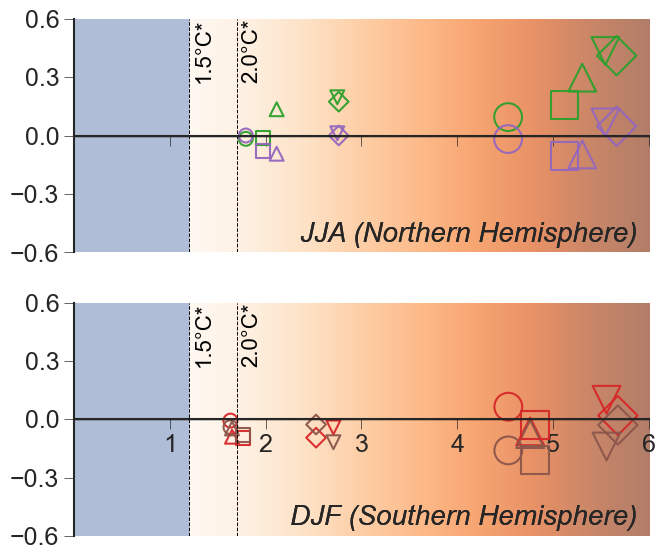

In [124]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')
plt.ion()

plt.rcParams.update({
    'font.family': 'Arial',  # Nature prefers Arial/Helvetica
})

# === FILE PATH ===
file_path = "Tas_SeasonalVSRunoff_rev1.xlsx"
df = pd.read_excel(file_path, sheet_name="Sheet1")
df.columns = df.columns.str.strip()

# Filter for Historical period and valid regions
df = df[df["Period"].isin(["126_Longterm", "585_Longterm"])]

# === REGION COLORS & MARKERS ===
model_markers = {
    'MIROC6': 'o',
    'NorESM2-LM': '^',      # Changed from 'x' to triangle for better visibility
    'NorESM2-MM': 's',      # Changed from '*' to square
    'CMCC-CM2-SR5': 'D',    # Changed from '+' to diamond
    'CMCC-ESM2': 'v',       # Changed from 'd' to inverted triangle
    'ERA5': 'p'             # Changed from 's' to pentagon
}

# === PERIOD SIZES ===
period_sizes = {
    '126_Longterm': 100,   # Smaller size for 126_Midterm
    '585_Longterm': 400    # Larger size for 585_Midterm
}

region_colors = {
    'Subtropics_N': '#2ca02c',
    'Subtropics_S': '#d62728',
    'Mid_Latitudes_N': '#9467bd',
    'Mid_Latitudes_S': '#8c564b'
}

# === SETUP SUBPLOTS ===
sns.set(style="ticks", context="talk")
fig, axs = plt.subplots(2, 1, figsize=(7, 6), sharex=True, sharey=True)

subplot_settings = [
    {
        "season": "JJA",
        "regions": ["Mid_Latitudes_N", "Subtropics_N"],
        "ax": axs[0],
        "title": "JJA: Northern Hemisphere"
    },
    {
        "season": "DJF",
        "regions": ["Mid_Latitudes_S", "Subtropics_S"],
        "ax": axs[1],
        "title": "DJF: Southern Hemisphere"
    }
]

# Determine axis limits globally
x_all = df["Global_Temp_change_°C"]
y_all = df["Regional_change_mm/day"]
data_max = max(x_all.max(), y_all.max(), 2.0)

for i, setting in enumerate(subplot_settings):
    sub_df = df[(df["Season"] == setting["season"]) & (df["Region"].isin(setting["regions"]))]
    ax = setting["ax"]
    sub_df["Region"] = pd.Categorical(sub_df["Region"], categories=setting["regions"], ordered=True)

    # === ADD BACKGROUND COLOR REGIONS FOR EACH SUBPLOT ===
    # Light red background for 0 < X < 1.2
    #ax.axvspan(0, 1.2, alpha=0.1, color='#e5f5f9', zorder=0)
    # Darker red background for 1.2 < X < 1.5
    #ax.axvspan(1.2, 1.7, alpha=0.6, color='#e5f5f9', zorder=0)
    #ax.axvspan(1.7, 5.0, alpha=1.0, color='#e5f5f9', zorder=0)

    ax.axvspan(0, 1.2, alpha=1.0, color='#B0BDD6', zorder=0)

    gradient = np.linspace(0, 1, 256).reshape(1, 256)
    ax.imshow(gradient, aspect='auto', cmap='Oranges',
              extent=[1.2, 6.0, -0.6, 0.6],
              origin='lower', alpha=0.6, zorder=0)

    for model, marker in model_markers.items():
        model_df = sub_df[sub_df["Model"] == model]
        for _, row in model_df.iterrows():
            color = region_colors.get(row["Region"], "gray")
            
            # Get size based on period
            size = period_sizes.get(row["Period"], 40)
            
            # All markers are unfilled (outline only)
            ax.scatter(
                row["Global_Temp_change_°C"],
                row["Regional_change_mm/day"],
                marker=marker,
                s=size,
                edgecolor=color,
                facecolor='none',  # No fill for all markers
                linewidth=1.5,     # Slightly thicker edge for better visibility
                alpha=0.95
            )

    x_max = 6
    y_min = -0.6
    y_max = 0.6
    xticks = np.arange(1, x_max + 0.01, 1)
    yticks = np.arange(y_min, y_max + 0.01, 0.3)
    yticks = np.append(yticks, 0)
    yticks = np.unique(yticks)

    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)

    # === REMOVE FRAME - keep only X and Y axes ===
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(1.5)
    ax.spines['bottom'].set_visible(True)
    ax.spines['left'].set_visible(True)
    ax.spines['left'].set_linewidth(1.5)
    
    # Keep baseline at Y=0
    ax.axhline(y=0, color='black', linestyle='-', linewidth=1)

    # Move X-axis and its labels to Y=0
    ax.spines['bottom'].set_position('zero')  # Move X-axis to Y=0
    ax.tick_params(axis='x', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)
    ax.tick_params(axis='y', which='major', length=7, width=0.5, direction='out', 
                   labelsize=18)

    # Inline labels at end of lines
    ax.text(1.2 + 0.05, 0.6, '1.5°C*', color='black', fontsize=16, rotation=90, va='top')
    ax.text(1.7 + 0.05, 0.6, '2.0°C*', color='black', fontsize=16, rotation=90, va='top')

    ax.axvline(x=1.2, color='black', linestyle='--', linewidth=0.7)
    ax.axvline(x=1.7, color='black', linestyle='--', linewidth=0.7)

    #ax.set_title(setting["title"], fontsize=16)

    # === ANNOTATIONS FOR SEASONS ===
    axs[0].text(0.98, 0.02, 'JJA (Northern Hemisphere)', transform=axs[0].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')
    axs[1].text(0.98, 0.02, 'DJF (Southern Hemisphere)', transform=axs[1].transAxes,
           fontsize=20, ha='right', va='bottom', style='italic')

    ax.grid(False)

# === Shared Legend BELOW plots ===
region_legend = [
    Line2D([0], [0], marker='o', color='w', label=region,
           markerfacecolor='none', markeredgecolor=color, markersize=6, linestyle='None')
    for region, color in region_colors.items()
]

reference_legend = [
    Line2D([0], [0], color='gray', linestyle='--', label="IPCC Limit (1.5°C and 2.0°C)"),
    Line2D([0], [0], color='black', linestyle='-', label="Y=0 Baseline"),
]

# === Adjust Layout ===
plt.subplots_adjust(hspace=0.2)
plt.tight_layout(rect=[0, 0.01, 1, 1])  # Leave space for legend
plt.savefig("Global_Temp_vs_q_Summer2.png", dpi=800, bbox_inches='tight')
print("Figure saved as 'Global_Temp_vs_q_Summer2.png'")
plt.show()